# Costo para Regresión Logística

Desde el Lab 02 medimos el error con el costo cuadrático (MSE): promediar $(f - y)^2$. Funcionaba porque el modelo era una recta y el costo tenía forma de tazón (bowl): un solo mínimo global al que el Descenso del Gradiente siempre llega.

Con la sigmoide eso se rompe. Al meter $g(z)$ dentro del cuadrado, la superficie de $J(w,b)$ deja de ser un tazón: aparecen zonas planas y valles extra (mínimos locales) donde el gradiente se estanca o se queda atrapado. El MSE penaliza *distancias*, pero clasificar es una pregunta de *lado correcto con confianza*, y el cuadrado no sabe expresar eso: un error seguro (predecir $0.01$ cuando es $1$) cuesta como máximo $1$, igual que cualquier otro error grande.

Necesitamos un costo diseñado para probabilidades. Ese costo es la pérdida logarítmica.

### La pérdida logarítmica (log loss), por casos

Para un solo ejemplo, el costo depende de la etiqueta real:

- Si $y = 1$: $L = -\log(f)$, donde $f = g(z)$ es la probabilidad predicha.
- Si $y = 0$: $L = -\log(1 - f)$.

La intuición con números (caso $y = 1$, tumor realmente maligno):

- Predices $f = 0.9$ (seguro y correcto): $L = -\log(0.9) \approx 0.11$. Casi nada.
- Predices $f = 0.1$ (seguro y equivocado): $L = -\log(0.1) \approx 2.30$. Caro.
- Si la predicción se acerca a $f = 0$ (totalmente seguro y totalmente mal): el costo tiende a **infinito**. El modelo aprende a nunca estar seguro de lo incorrecto.

El caso $y = 0$ es el espejo: cuesta $-\log(1 - f)$, o sea ~$0$ si predices $f = 0.1$ e infinito si predices $f = 1.0$.

In [1]:
import numpy as np

def logistic_loss(f_wb, y):
    """
    Calcula la pérdida logarítmica de un ejemplo.
    Args:
      f_wb (scalar): probabilidad predicha g(z), entre 0 y 1
      y (scalar): etiqueta real (0 o 1)
    Returns:
      loss (scalar): costo del ejemplo
    """
    if y == 1:
        return -np.log(f_wb)
    return -np.log(1 - f_wb)

# Paso 1: Calcular el costo a mano en los 4 casos
for f_ej, y_ej in [(0.9, 1), (0.1, 1), (0.1, 0), (0.9, 0)]:
    print(f"y = {y_ej}, f = {f_ej}: L = {logistic_loss(f_ej, y_ej):.2f}")

print(f"y = 1, f -> 0: L tiende a infinito (aquí f = 0.001: L = {logistic_loss(0.001, 1):.2f})")

y = 1, f = 0.9: L = 0.11
y = 1, f = 0.1: L = 2.30
y = 0, f = 0.1: L = 0.11
y = 0, f = 0.9: L = 2.30
y = 1, f -> 0: L tiende a infinito (aquí f = 0.001: L = 6.91)


### En una línea: el costo total $J(w,b)$

Como $y$ solo vale $0$ o $1$, exactamente uno de los dos términos sobrevive. Eso permite escribir la pérdida en una sola línea:

$$L(f, y) = -\left[ y \log(f) + (1 - y) \log(1 - f) \right]$$

Si $y = 1$, el segundo término se anula y queda $-\log(f)$. Si $y = 0$, se anula el primero y queda $-\log(1 - f)$. Y el costo total es el promedio sobre los $m$ ejemplos:

$$J(w,b) = \frac{1}{m} \sum_{i=1}^{m} L(f^{(i)}, y^{(i)})$$

(Sin el $\frac{1}{2}$ del MSE: aquí no hay cuadrado que derivar, el $2$ ya no simplifica nada.)

La recompensa: con esta $J$, la superficie **vuelve a ser convexa** (un tazón con un solo mínimo global). El Descenso del Gradiente del Lab 03 funciona igual que siempre; lo único que cambia es la fórmula del gradiente, que es el siguiente tema.

MSE: mínimo 0.0223 en w = 1.04, tope 0.25
LOG: mínimo 0.1892 en w = 1.08, |gradiente| en w=-2: 3.25 vs MSE: 0.00


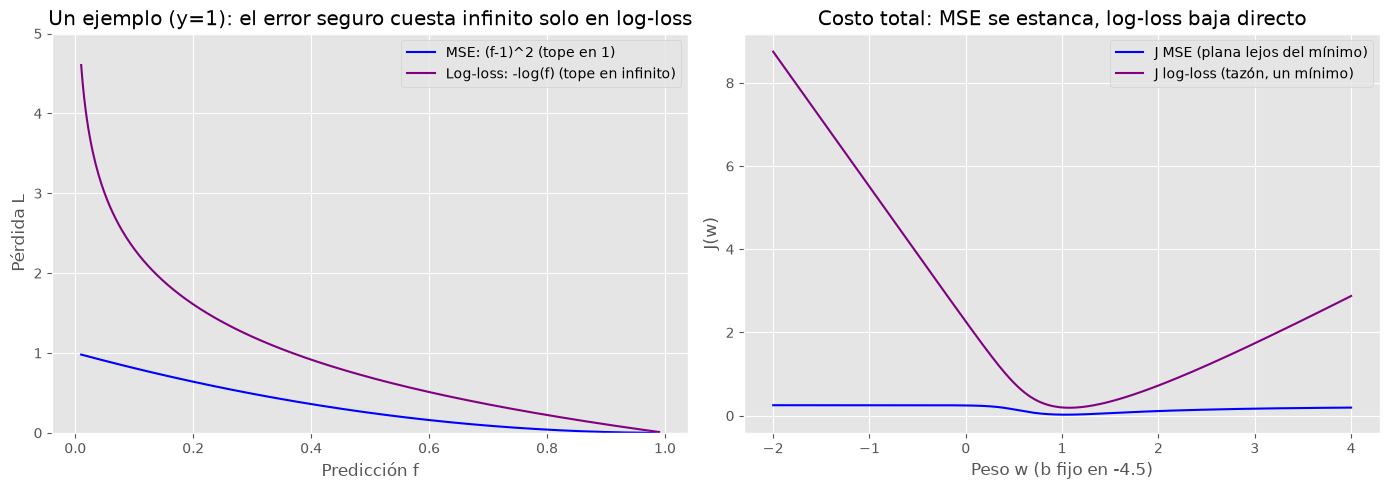

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Estilo para las gráficas
plt.style.use('ggplot')

def sigmoid(z):
    """Calcula la función sigmoide g(z) = 1 / (1 + e^(-z))."""
    return 1 / (1 + np.exp(-z))

# Panel A: pérdidas de un ejemplo con y = 1 según la predicción f
f = np.linspace(0.01, 0.99, 400)
mse_1 = (f - 1) ** 2
log_1 = -np.log(f)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(f, mse_1, c='b', label='MSE: (f-1)^2 (tope en 1)')
ax1.plot(f, log_1, c='purple', label='Log-loss: -log(f) (tope en infinito)')
ax1.set_title("Un ejemplo (y=1): el error seguro cuesta infinito solo en log-loss")
ax1.set_xlabel("Predicción f")
ax1.set_ylabel("Pérdida L")
ax1.set_ylim(0, 5)
ax1.legend()

# Panel B: J(w) con b fijo sobre tumores — MSE plana lejos del mínimo, log-loss tazón
x = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0])
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])
b = -4.5
ws = np.linspace(-2, 4, 400)
eps = 1e-12

J_mse = np.array([((sigmoid(w * x + b) - y) ** 2).mean() / 2 for w in ws])
J_log = np.array([-(y * np.log(np.clip(sigmoid(w * x + b), eps, 1))
                    + (1 - y) * np.log(np.clip(1 - sigmoid(w * x + b), eps, 1))).mean()
                    for w in ws])

print(f"MSE: mínimo {J_mse.min():.4f} en w = {ws[np.argmin(J_mse)]:.2f}, tope {J_mse.max():.2f}")
print(f"LOG: mínimo {J_log.min():.4f} en w = {ws[np.argmin(J_log)]:.2f}, |gradiente| en w=-2: {abs(np.gradient(J_log, ws)[0]):.2f} vs MSE: {abs(np.gradient(J_mse, ws)[0]):.2f}")

ax2.plot(ws, J_mse, c='b', label='J MSE (plana lejos del mínimo)')
ax2.plot(ws, J_log, c='purple', label='J log-loss (tazón, un mínimo)')
ax2.set_title("Costo total: MSE se estanca, log-loss baja directo")
ax2.set_xlabel("Peso w (b fijo en -4.5)")
ax2.set_ylabel("J(w)")
ax2.legend()
plt.tight_layout()
plt.show()

### Cierre

- El MSE no sirve aquí: la sigmoide rompe el tazón y el gradiente se estanca o se atrapa.
- La pérdida logarítmica cuesta ~$0$ cuando aciertas seguro e infinito cuando fallas seguro.
- El costo total $J(w,b)$ promedia esa pérdida y vuelve a ser convexo: un solo mínimo global.
- El Descenso del Gradiente sigue igual; solo cambia la fórmula del gradiente, que es el siguiente tema.